In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


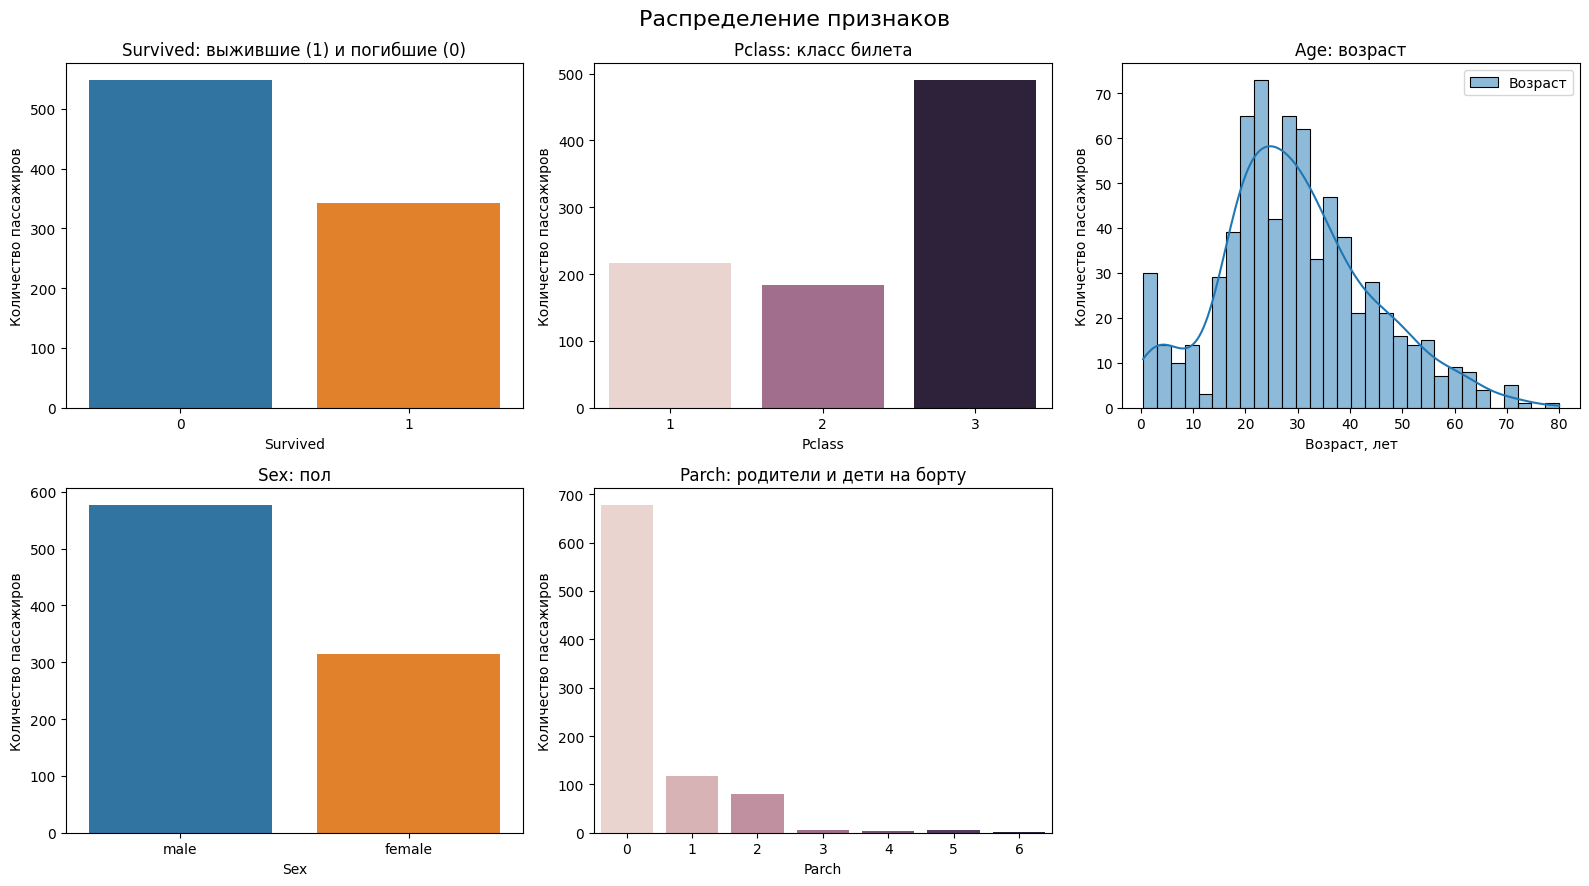

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Распределение признаков', fontsize=16)

sns.countplot(data=df, x='Survived', ax=axes[0, 0], hue='Survived', legend=False)
axes[0, 0].set_title('Survived: выжившие (1) и погибшие (0)')
axes[0, 0].set_xlabel('Survived')
axes[0, 0].set_ylabel('Количество пассажиров')

sns.countplot(data=df, x='Pclass', ax=axes[0, 1], hue='Pclass', legend=False)
axes[0, 1].set_title('Pclass: класс билета')
axes[0, 1].set_xlabel('Pclass')
axes[0, 1].set_ylabel('Количество пассажиров')

sns.histplot(data=df, x='Age', bins=30, kde=True, ax=axes[0, 2], label='Возраст')
axes[0, 2].set_title('Age: возраст')
axes[0, 2].set_xlabel('Возраст, лет')
axes[0, 2].set_ylabel('Количество пассажиров')
axes[0, 2].legend()

sns.countplot(data=df, x='Sex', ax=axes[1, 0], hue='Sex', legend=False)
axes[1, 0].set_title('Sex: пол')
axes[1, 0].set_xlabel('Sex')
axes[1, 0].set_ylabel('Количество пассажиров')

sns.countplot(data=df, x='Parch', ax=axes[1, 1], hue='Parch', legend=False)
axes[1, 1].set_title('Parch: родители и дети на борту')
axes[1, 1].set_xlabel('Parch')
axes[1, 1].set_ylabel('Количество пассажиров')

axes[1, 2].axis('off')   # лишняя ячейка сетки
plt.tight_layout()
plt.show()

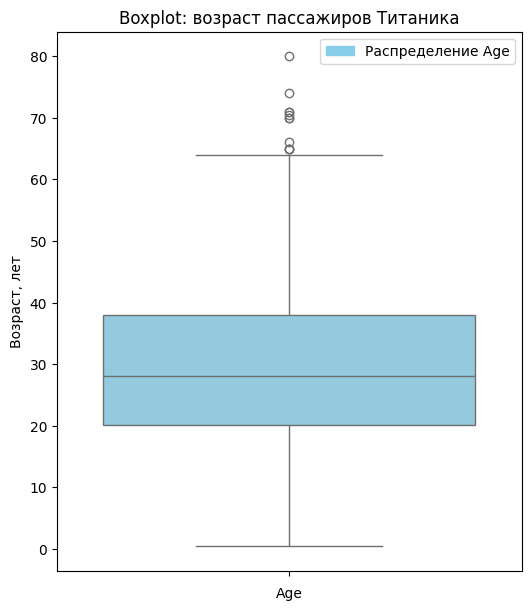

In [3]:
plt.figure(figsize=(6, 7))
sns.boxplot(y=df['Age'], color='skyblue')
plt.title('Boxplot: возраст пассажиров Титаника')
plt.ylabel('Возраст, лет')
plt.xlabel('Age')
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='skyblue')],
           labels=['Распределение Age'])
plt.show()

**Интерпретация графика**

Возраст известен у 714 из 891 пассажиров (у 177 пропуски).
Медиана возраста около 28 лет: половина пассажиров моложе 28.
Середина данных (между первым и третьим квартилями) лежит примерно от 20 до 38 лет, то есть основная масса пассажиров это молодые и среднего возраста люди.
Среднее (около 29,7) немного выше медианы, что говорит о небольшой правосторонней асимметрии: пожилые пассажиры «тянут» среднее вверх.
Нижний «ус» доходит до минимума (младенцы, 0,42 года), нижних выбросов нет.
Выше верхней границы (около 65 лет) находятся 11 выбросов, максимальный возраст 80 лет.
Это реальные пожилые пассажиры, а не ошибки данных, поэтому удалять выбросы не нужно.

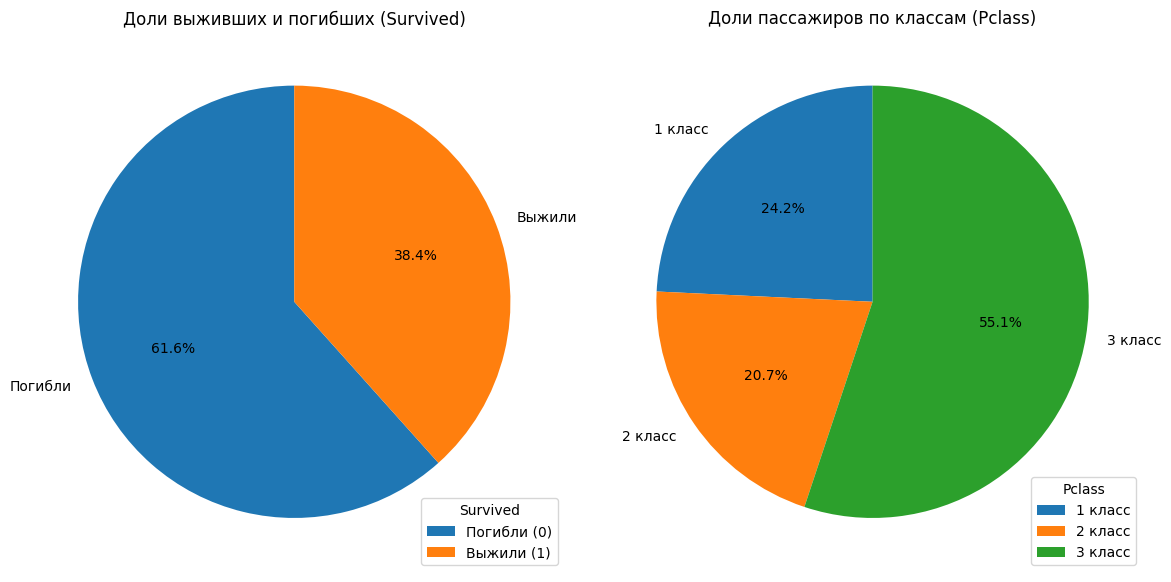

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

survived_counts = df['Survived'].value_counts().sort_index()
axes[0].pie(survived_counts, labels=['Погибли', 'Выжили'],
            autopct='%1.1f%%', startangle=90)
axes[0].set_title('Доли выживших и погибших (Survived)')
axes[0].legend(['Погибли (0)', 'Выжили (1)'], title='Survived', loc='lower right')

pclass_counts = df['Pclass'].value_counts().sort_index()
axes[1].pie(pclass_counts, labels=['1 класс', '2 класс', '3 класс'],
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Доли пассажиров по классам (Pclass)')
axes[1].legend(['1 класс', '2 класс', '3 класс'], title='Pclass', loc='lower right')

plt.tight_layout()
plt.show()

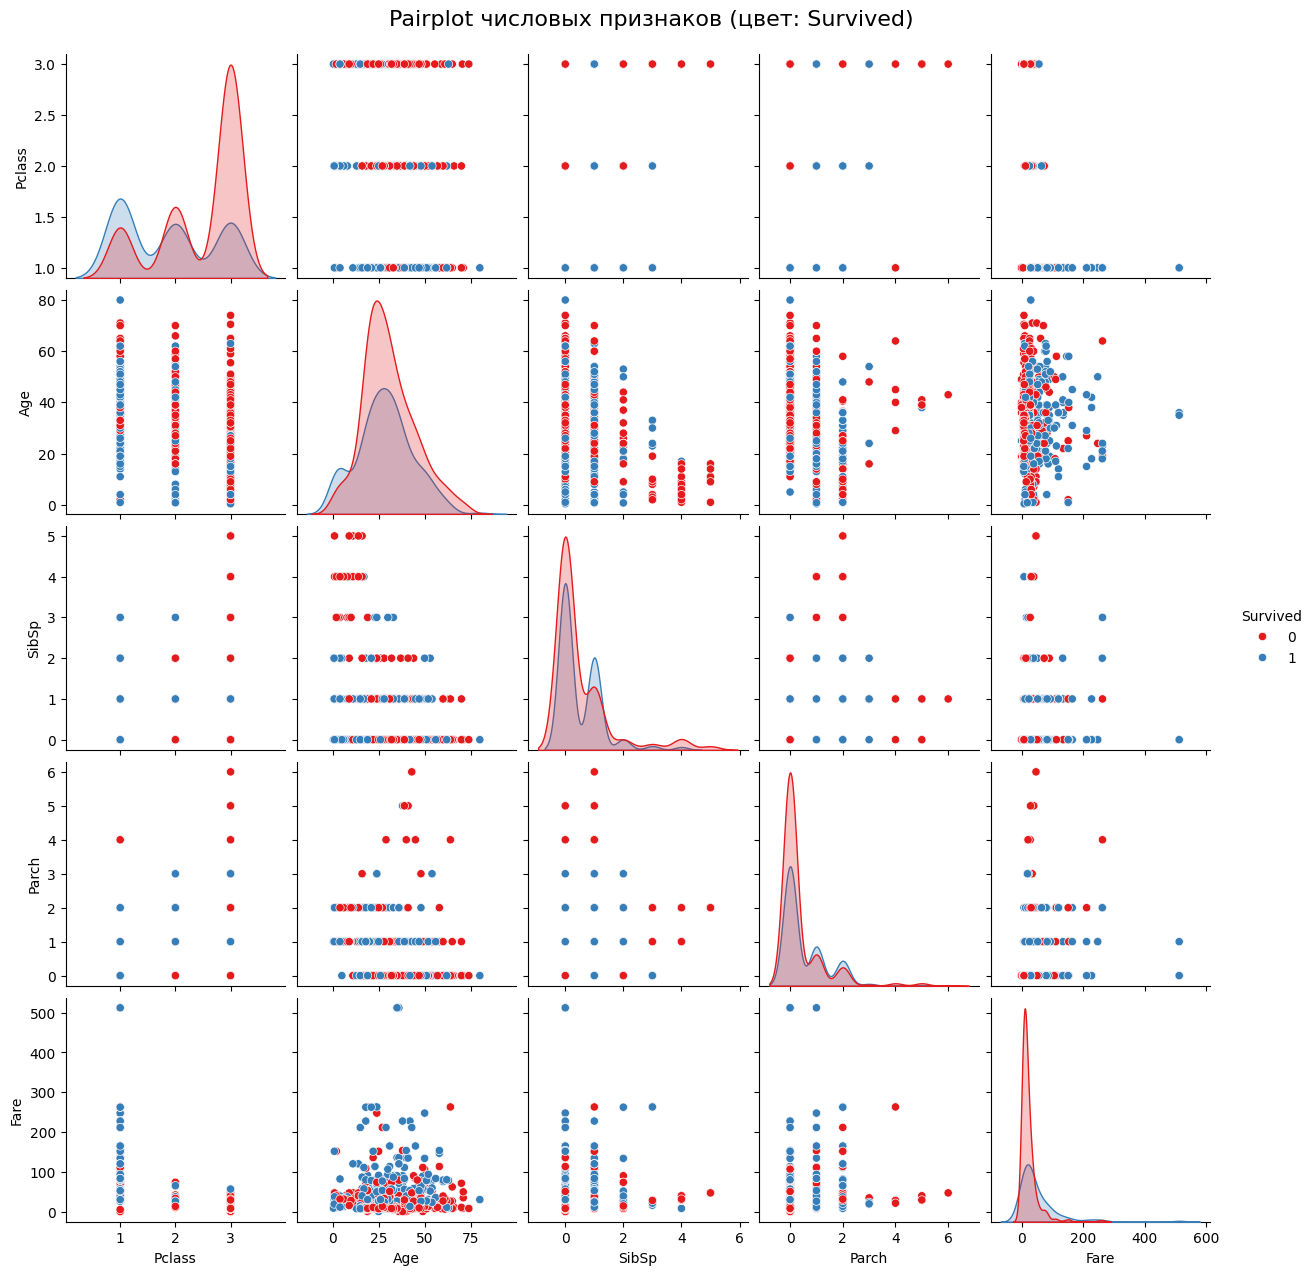

In [5]:
num_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

g = sns.pairplot(df[num_cols].dropna(), hue='Survived', palette='Set1')
g.figure.suptitle('Pairplot числовых признаков (цвет: Survived)', y=1.02, fontsize=16)
plt.show()

In [6]:
sun_df = df.groupby(['Pclass', 'Sex']).size().reset_index(name='Count')
sun_df['Pclass'] = sun_df['Pclass'].astype(str) + ' класс'
sun_df['Sex'] = sun_df['Sex'].map({'male': 'Мужчины', 'female': 'Женщины'})

fig = px.sunburst(
    sun_df,
    path=['Pclass', 'Sex'],
    values='Count',
    color='Sex',
    title='Пассажиры Титаника по классам и полу',
)
fig.update_layout(legend_title_text='Пол', width=650, height=650)
fig.show()